In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
print(df.info())
print(df['Churn'].value_counts())

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [2]:
# Missing values 
print(df.isnull().sum())

# TotalCharges column convert numeric  
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].isnull().sum())   # 11 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
11


In [3]:
df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)

# remove customerID column since it is not useful for prediction
df = df.drop('customerID', axis=1)
print(df.shape)   # (7032, 20)

(7032, 20)


In [4]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df['Churn'].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [5]:
df_encoded = pd.get_dummies(df, drop_first=True)
print(df_encoded.shape)   # columns ~30 
df_encoded = df_encoded.astype(float)

(7032, 31)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # train එකෙන් විතරක් fit
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, lr_pred))
print(confusion_matrix(y_test, lr_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))

              precision    recall  f1-score   support

         0.0       0.91      0.70      0.79      1033
         1.0       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

[[724 309]
 [ 76 298]]
ROC-AUC: 0.8349765233911922


In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

# Class weights (imbalance)
weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print(class_weight)

model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1
)

{0: np.float64(0.6809927360774818), 1: np.float64(1.8812709030100334)}


c:\Users\Hp\Downloads\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6607 - auc: 0.7019 - loss: 0.6341 - val_accuracy: 0.7102 - val_auc: 0.8144 - val_loss: 0.5354
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7100 - auc: 0.7778 - loss: 0.5685 - val_accuracy: 0.7218 - val_auc: 0.8386 - val_loss: 0.5146
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7156 - auc: 0.7986 - loss: 0.5438 - val_accuracy: 0.7511 - val_auc: 0.8442 - val_loss: 0.4906
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7289 - auc: 0.8115 - loss: 0.5337 - val_accuracy: 0.7449 - val_auc: 0.8492 - val_loss: 0.5067
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7358 - auc: 0.8243 - loss: 0.5150 - val_accuracy: 0.7582 - val_auc: 0.8521 - val_loss: 0.4856
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7416 - auc: 0.8277 - loss: 0.5108 - val_accuracy: 0.7556 - val_auc: 0.8541 - val_loss: 0.4911
Epoch 7/100
141/141 ━━━━━━━━━━━━━━

In [9]:
ann_prob = model.predict(X_test).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)

print(classification_report(y_test, ann_pred))
print(confusion_matrix(y_test, ann_pred))
print("ROC-AUC:", roc_auc_score(y_test, ann_prob))


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

         0.0       0.90      0.72      0.80      1033
         1.0       0.50      0.79      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.80      0.74      0.75      1407

[[743 290]
 [ 80 294]]
ROC-AUC: 0.8314873868230738


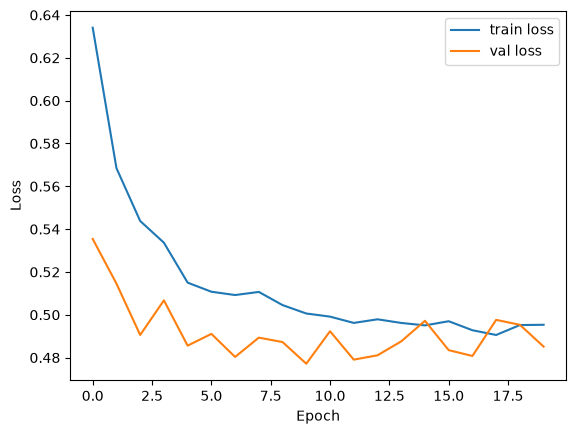

In [10]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
print("RF ROC-AUC:", roc_auc_score(y_test, rf_prob))

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_prob = gb.predict_proba(X_test)[:, 1]
print("GB ROC-AUC:", roc_auc_score(y_test, gb_prob))

RF ROC-AUC: 0.8204375915639511
GB ROC-AUC: 0.8406619005958451


In [12]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, ann_prob)
for t in [0.4, 0.5, 0.6, 0.7]:
    pred = (ann_prob >= t).astype(int)
    print(t)
    print(classification_report(y_test, pred, digits=2))

0.4
              precision    recall  f1-score   support

         0.0       0.93      0.59      0.72      1033
         1.0       0.44      0.88      0.59       374

    accuracy                           0.67      1407
   macro avg       0.69      0.74      0.66      1407
weighted avg       0.80      0.67      0.69      1407

0.5
              precision    recall  f1-score   support

         0.0       0.90      0.72      0.80      1033
         1.0       0.50      0.79      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.80      0.74      0.75      1407

0.6
              precision    recall  f1-score   support

         0.0       0.87      0.81      0.84      1033
         1.0       0.56      0.68      0.62       374

    accuracy                           0.78      1407
   macro avg       0.72      0.74      0.73      1407
weighted avg       0.79      0.78      0.78      1407

0.7
   

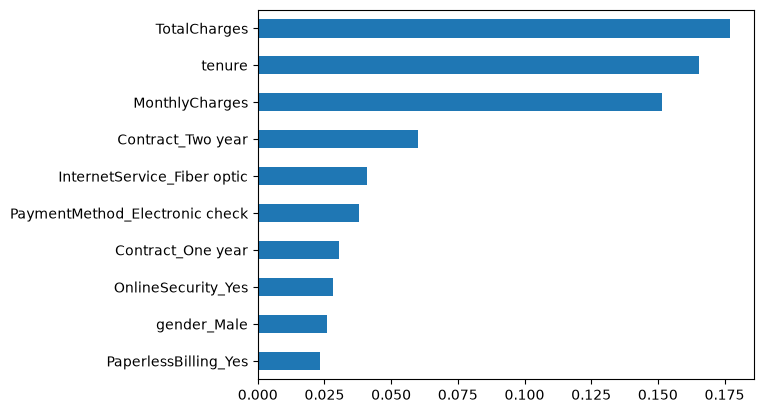

In [13]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh'); plt.gca().invert_yaxis(); plt.show()

In [15]:
import joblib, json

model.save("churn_ann.keras")
joblib.dump(scaler, "scaler.pkl")

# column නම් (app එකේ එකම පිළිවෙලට ඕන)
with open("columns.json", "w") as f:
    json.dump(list(X.columns), f)

print(list(X.columns))

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
